In [1]:

from google.colab import files

uploaded = files.upload()


Saving household_power_consumption.txt to household_power_consumption.txt


In [2]:

import pandas as pd
import numpy as np

df = pd.read_csv(
    'household_power_consumption.txt',
    sep=';',
    na_values=['?'],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()



Dataset loaded successfully!
Shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:

print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)



Rows and columns: (2075259, 9)

Column names:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

Missing values:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Data types:
Date                      object
Time                      object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


In [4]:

# Check how missing values are distributed

numeric_cols = df.select_dtypes(include=np.number).columns

missing_rows = df[numeric_cols].isnull().sum(axis=1)

print("Rows with at least one missing value:",
      (missing_rows > 0).sum())

print("\nRows where all numerical values are missing:",
      (missing_rows == len(numeric_cols)).sum())

print("\nMissing values per row:")
print(missing_rows.value_counts().sort_index())


Rows with at least one missing value: 25979

Rows where all numerical values are missing: 25979

Missing values per row:
0    2049280
7      25979
Name: count, dtype: int64


In [5]:

# Check duplicate records

print("Total duplicate rows:",
      df.duplicated().sum())

print("Duplicate date-time records:",
      df.duplicated(subset=['Date', 'Time']).sum())


Total duplicate rows: 0
Duplicate date-time records: 0


In [6]:

# Create a combined DateTime column

df['DateTime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Time'],
    format='%d/%m/%Y %H:%M:%S',
    errors='coerce'
)

print(df[['Date', 'Time', 'DateTime']].head())

print("\nDateTime data type:")
print(df['DateTime'].dtype)

print("\nInvalid timestamps:",
      df['DateTime'].isna().sum())


         Date      Time            DateTime
0  16/12/2006  17:24:00 2006-12-16 17:24:00
1  16/12/2006  17:25:00 2006-12-16 17:25:00
2  16/12/2006  17:26:00 2006-12-16 17:26:00
3  16/12/2006  17:27:00 2006-12-16 17:27:00
4  16/12/2006  17:28:00 2006-12-16 17:28:00

DateTime data type:
datetime64[ns]

Invalid timestamps: 0


In [7]:

# Identify continuous periods of missing electricity readings

df['Missing'] = df[numeric_cols].isnull().all(axis=1)

# Group consecutive missing and non-missing records
groups = df['Missing'].ne(df['Missing'].shift()).cumsum()

# Find continuous missing periods
missing_periods = (
    df[df['Missing']]
    .groupby(groups)
    .agg(
        Start=('DateTime', 'min'),
        End=('DateTime', 'max'),
        Missing_Minutes=('DateTime', 'count')
    )
)

print("Total continuous missing periods:",
      len(missing_periods))

print("\nLongest missing periods:")
print(
    missing_periods
    .sort_values('Missing_Minutes', ascending=False)
    .head(10)
)


Total continuous missing periods: 71

Longest missing periods:
                      Start                 End  Missing_Minutes
Missing                                                         
138     2010-08-17 21:02:00 2010-08-22 21:27:00             7226
140     2010-09-25 03:56:00 2010-09-28 19:12:00             5237
14      2007-04-28 00:21:00 2007-04-30 14:23:00             3723
100     2009-06-13 00:30:00 2009-06-15 07:34:00             3305
118     2010-01-12 14:53:00 2010-01-14 19:01:00             3129
126     2010-03-20 03:52:00 2010-03-21 13:38:00             2027
104     2009-08-13 05:00:00 2009-08-13 19:50:00              891
32      2007-07-15 16:49:00 2007-07-15 18:11:00               83
78      2008-12-10 10:48:00 2008-12-10 11:57:00               70
34      2007-07-15 18:21:00 2007-07-15 19:07:00               47


In [8]:

# Statistical summary before cleaning

df[numeric_cols].describe()


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


In [10]:

# Create a copy of the original dataset
df_clean = df.copy()

# Remove rows where all numerical readings are missing
df_clean = df_clean.dropna(subset=numeric_cols).copy()

# Remove temporary missing-value indicator if present
if 'Missing' in df_clean.columns:
    df_clean.drop(columns=['Missing'], inplace=True)

# Reset index
df_clean.reset_index(drop=True, inplace=True)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean[numeric_cols].isnull().sum())

print("\nRemaining duplicate records:",
      df_clean.duplicated().sum())


Original dataset shape: (2075259, 11)
Cleaned dataset shape: (2049280, 10)

Missing values after cleaning:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

Remaining duplicate records: 0


In [11]:

# Check negative values in numerical columns

negative_counts = (df_clean[numeric_cols] < 0).sum()

print("Negative values in each column:")
print(negative_counts)

print("\nMinimum values after cleaning:")
print(df_clean[numeric_cols].min())


Negative values in each column:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

Minimum values after cleaning:
Global_active_power        0.076
Global_reactive_power      0.000
Voltage                  223.200
Global_intensity           0.200
Sub_metering_1             0.000
Sub_metering_2             0.000
Sub_metering_3             0.000
dtype: float64


In [12]:

# Outlier detection using IQR method

outlier_results = []

for col in numeric_cols:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ]

    outlier_results.append({
        'Column': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Limit': lower,
        'Upper Limit': upper,
        'Outlier Count': len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)

print(outlier_df.to_string(index=False))


               Column      Q1      Q3    IQR  Lower Limit  Upper Limit  Outlier Count
  Global_active_power   0.308   1.528  1.220       -1.522        3.358          94907
Global_reactive_power   0.048   0.194  0.146       -0.171        0.413          40420
              Voltage 238.990 242.890  3.900      233.140      248.740          51067
     Global_intensity   1.400   6.400  5.000       -6.100       13.900         100961
       Sub_metering_1   0.000   0.000  0.000        0.000        0.000         169105
       Sub_metering_2   0.000   1.000  1.000       -1.500        2.500          77151
       Sub_metering_3   0.000  17.000 17.000      -25.500       42.500              0


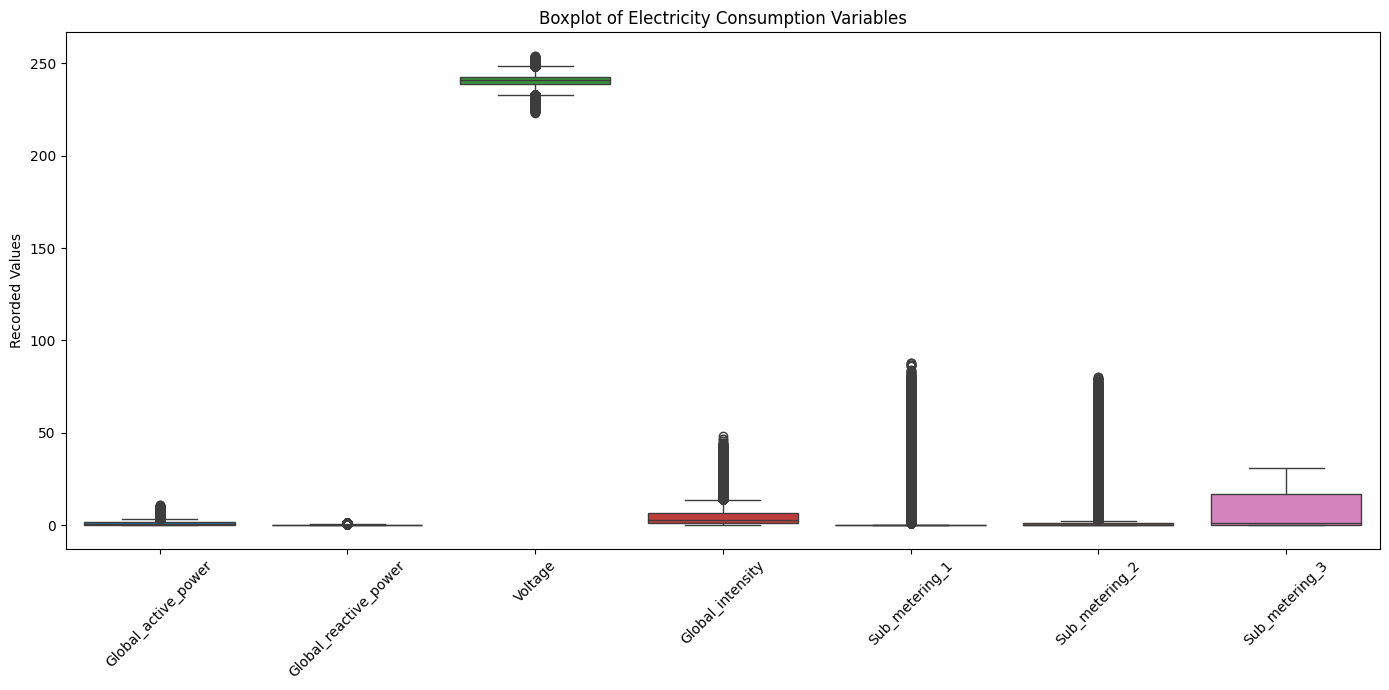

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

sns.boxplot(data=df_clean[numeric_cols])

plt.title("Boxplot of Electricity Consumption Variables")
plt.xticks(rotation=45)
plt.ylabel("Recorded Values")
plt.tight_layout()
plt.show()


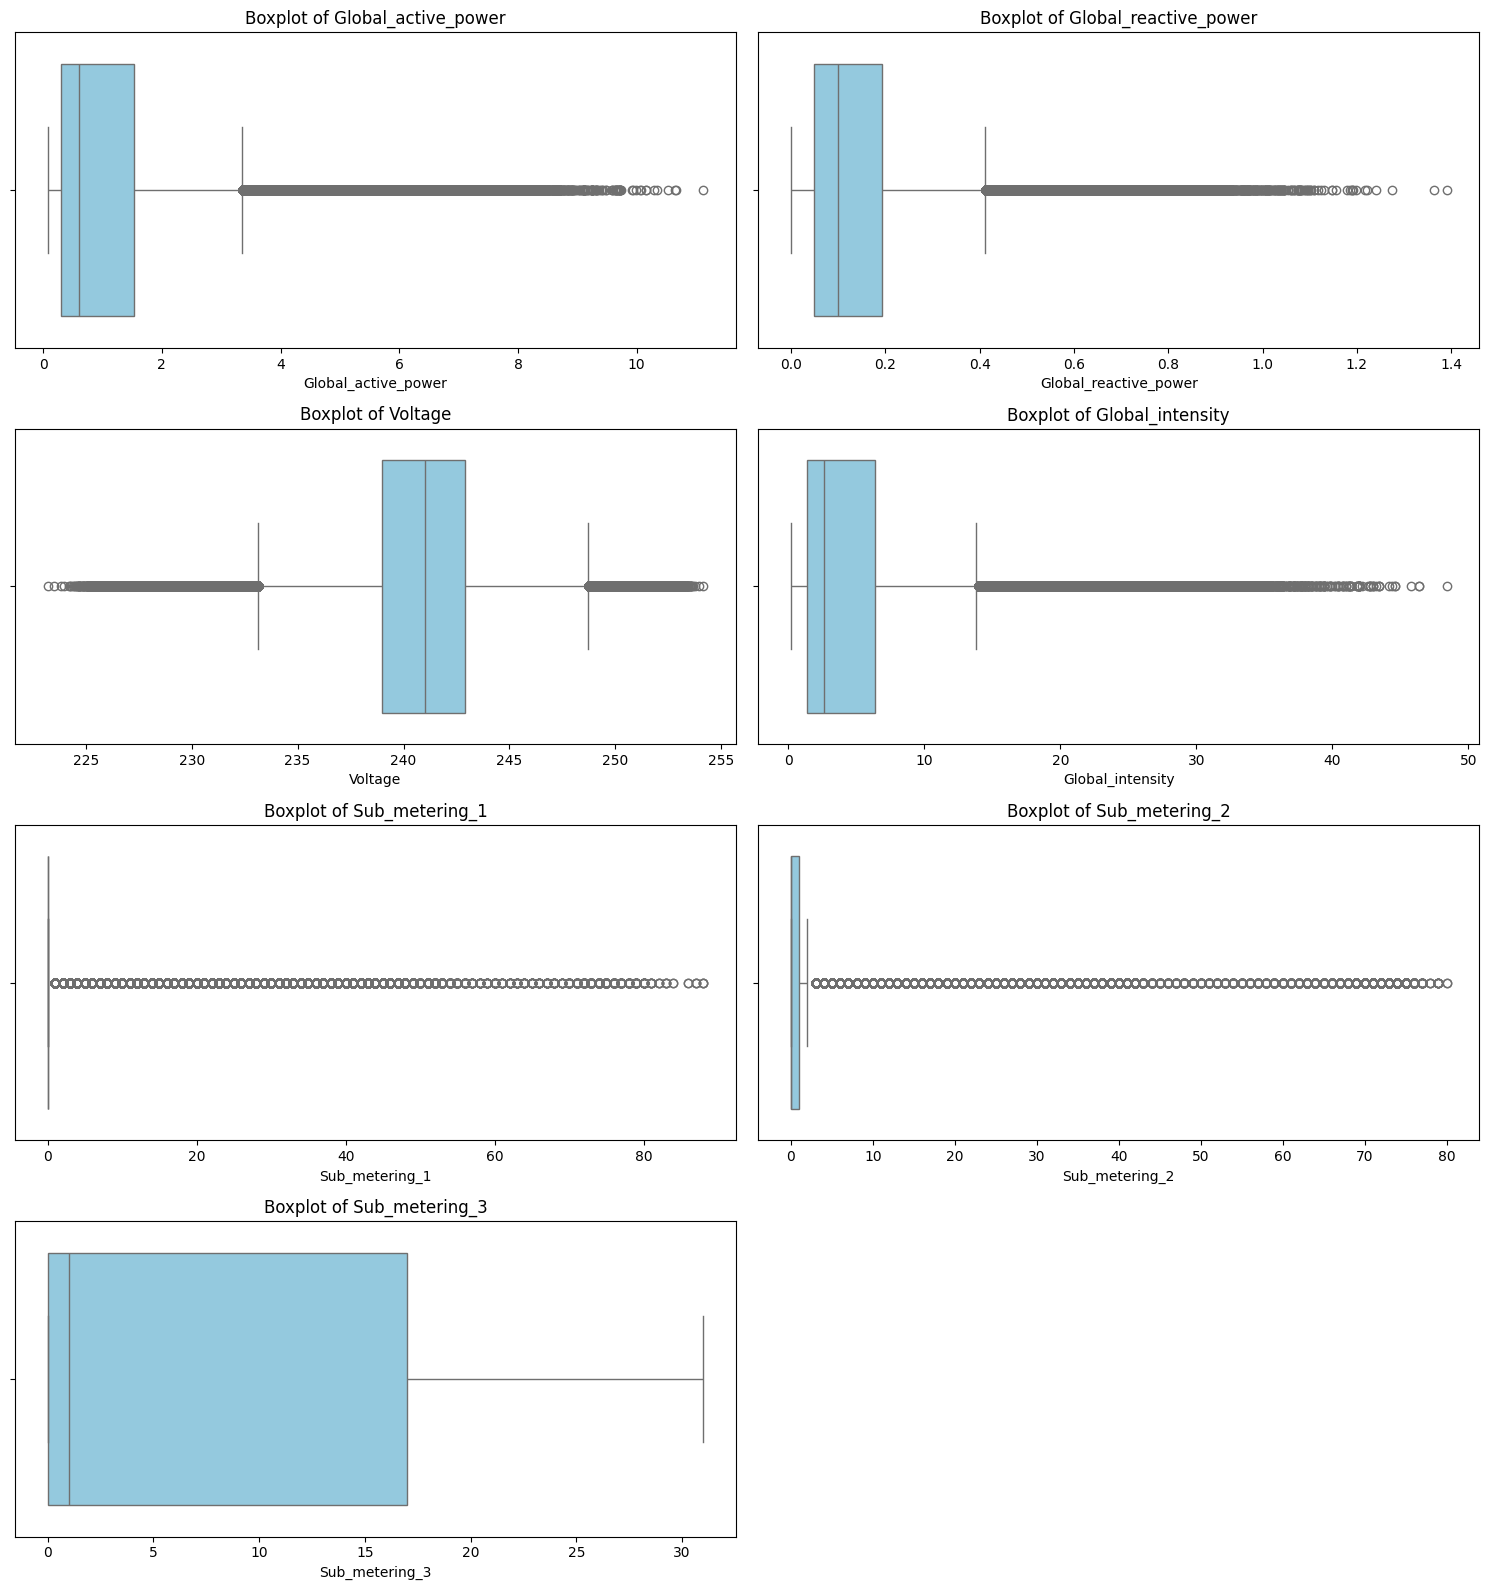

In [14]:

# Individual boxplots for each numerical variable

fig, axes = plt.subplots(4, 2, figsize=(15, 16))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):

    sns.boxplot(
        x=df_clean[col],
        ax=axes[i],
        color='skyblue'
    )

    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_xlabel(col)

axes[-1].axis('off')

plt.tight_layout()
plt.show()


In [17]:
# Convert list into DataFrame
outlier_results = pd.DataFrame(outlier_results)

# Calculate percentage of potential outliers
outlier_results['Outlier Percentage'] = (
    outlier_results['Outlier Count'] / len(df_clean) * 100
)

# Display results
print(
    outlier_results[
        ['Column', 'Outlier Count', 'Outlier Percentage']
    ].round(2).to_string(index=False)
)

               Column  Outlier Count  Outlier Percentage
  Global_active_power          94907                4.63
Global_reactive_power          40420                1.97
              Voltage          51067                2.49
     Global_intensity         100961                4.93
       Sub_metering_1         169105                8.25
       Sub_metering_2          77151                3.76
       Sub_metering_3              0                0.00


In [18]:

# Final validation of cleaned dataset

print("Dataset shape:", df_clean.shape)

print("\nData types:")
print(df_clean.dtypes)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate records:")
print(df_clean.duplicated().sum())

print("\nDateTime range:")
print(df_clean['DateTime'].min())
print(df_clean['DateTime'].max())

print("\nStatistical summary:")
print(df_clean[numeric_cols].describe())


Dataset shape: (2049280, 10)

Data types:
Date                             object
Time                             object
Global_active_power             float64
Global_reactive_power           float64
Voltage                         float64
Global_intensity                float64
Sub_metering_1                  float64
Sub_metering_2                  float64
Sub_metering_3                  float64
DateTime                 datetime64[ns]
dtype: object

Missing values:
Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
DateTime                 0
dtype: int64

Duplicate records:
0

DateTime range:
2006-12-16 17:24:00
2010-11-26 21:02:00

Statistical summary:
       Global_active_power  Global_reactive_power       Voltage  \
count         2.049280e+06           2.049280e+06  2.049280e+06   
mean     

In [19]:

# Sort dataset chronologically
df_clean = df_clean.sort_values('DateTime').reset_index(drop=True)

# Calculate time difference between consecutive records
df_clean['Time_Difference'] = df_clean['DateTime'].diff()

print("Time interval distribution:")
print(df_clean['Time_Difference'].value_counts().head(10))

# Count gaps greater than one minute
gaps = df_clean[df_clean['Time_Difference'] > pd.Timedelta(minutes=1)]

print("\nNumber of gaps:", len(gaps))
print("\nLargest time gaps:")
print(gaps.nlargest(10, 'Time_Difference')[
    ['DateTime', 'Time_Difference']
])


Time interval distribution:
Time_Difference
0 days 00:01:00    2049208
0 days 00:02:00         38
0 days 00:03:00         14
0 days 00:04:00          2
2 days 14:04:00          1
0 days 00:34:00          1
0 days 01:24:00          1
0 days 00:48:00          1
0 days 00:22:00          1
0 days 00:44:00          1
Name: count, dtype: int64

Number of gaps: 71

Largest time gaps:
                   DateTime Time_Difference
1916303 2010-08-22 21:28:00 5 days 00:27:00
1964211 2010-09-28 19:13:00 3 days 15:18:00
190488  2007-04-30 14:24:00 2 days 14:04:00
1305243 2009-06-15 07:35:00 2 days 07:06:00
1608618 2010-01-14 19:02:00 2 days 04:10:00
1701305 2010-03-21 13:39:00 1 days 09:48:00
1390044 2009-08-13 19:51:00 0 days 14:52:00
300030  2007-07-15 18:12:00 0 days 01:24:00
1039605 2008-12-10 11:58:00 0 days 01:11:00
300039  2007-07-15 19:08:00 0 days 00:48:00


In [20]:

# Extract date and time features

df_clean['Year'] = df_clean['DateTime'].dt.year
df_clean['Month'] = df_clean['DateTime'].dt.month
df_clean['Day'] = df_clean['DateTime'].dt.day
df_clean['Hour'] = df_clean['DateTime'].dt.hour
df_clean['DayOfWeek'] = df_clean['DateTime'].dt.dayofweek

df_clean['Weekday_Name'] = df_clean['DateTime'].dt.day_name()

df_clean['Is_Weekend'] = (
    df_clean['DayOfWeek'] >= 5
).astype(int)

print(df_clean.head())


         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  \
0              18.4             0.0             1.0            17.0   
1              23.0             0.0             1.0            16.0   
2              23.0             0.0             2.0            17.0   
3              23.0             0.0             1.0            17.0   
4              15.8             0.0             1.0            17.0   

             DateTime Time_Difference  Year  Month  Day  Hour  DayOfWeek  \
0 2006-12-16 17:

In [21]:

# FINAL DATA VALIDATION

print("Dataset Shape:", df_clean.shape)

print("\n--- Missing Values ---")
print(df_clean.isnull().sum())

print("\n--- Duplicate Records ---")
print("Duplicates:", df_clean.duplicated().sum())

print("\n--- Data Types ---")
print(df_clean.dtypes)

print("\n--- DateTime Range ---")
print("Start:", df_clean['DateTime'].min())
print("End:", df_clean['DateTime'].max())

print("\n--- Statistical Summary ---")
numeric_cols = df_clean.select_dtypes(
    include=['number']
).columns

print(df_clean[numeric_cols].describe())


Dataset Shape: (2049280, 18)

--- Missing Values ---
Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
DateTime                 0
Time_Difference          1
Year                     0
Month                    0
Day                      0
Hour                     0
DayOfWeek                0
Weekday_Name             0
Is_Weekend               0
dtype: int64

--- Duplicate Records ---
Duplicates: 0

--- Data Types ---
Date                              object
Time                              object
Global_active_power              float64
Global_reactive_power            float64
Voltage                          float64
Global_intensity                 float64
Sub_metering_1                   float64
Sub_metering_2                   float64
Sub_metering_3                   float64
DateTime          

In [22]:

# CHECK TIME INTERVALS

df_clean = df_clean.sort_values('DateTime').reset_index(drop=True)

df_clean['Time_Difference'] = df_clean['DateTime'].diff()

print("Time interval distribution:")
print(df_clean['Time_Difference'].value_counts().head(10))

# Identify gaps greater than one minute
gaps = df_clean[
    df_clean['Time_Difference'] > pd.Timedelta(minutes=1)
]

print("\nTotal time gaps:", len(gaps))

print("\nLargest time gaps:")
print(
    gaps.nlargest(10, 'Time_Difference')[
        ['DateTime', 'Time_Difference']
    ]
)


Time interval distribution:
Time_Difference
0 days 00:01:00    2049208
0 days 00:02:00         38
0 days 00:03:00         14
0 days 00:04:00          2
2 days 14:04:00          1
0 days 00:34:00          1
0 days 01:24:00          1
0 days 00:48:00          1
0 days 00:22:00          1
0 days 00:44:00          1
Name: count, dtype: int64

Total time gaps: 71

Largest time gaps:
                   DateTime Time_Difference
1916303 2010-08-22 21:28:00 5 days 00:27:00
1964211 2010-09-28 19:13:00 3 days 15:18:00
190488  2007-04-30 14:24:00 2 days 14:04:00
1305243 2009-06-15 07:35:00 2 days 07:06:00
1608618 2010-01-14 19:02:00 2 days 04:10:00
1701305 2010-03-21 13:39:00 1 days 09:48:00
1390044 2009-08-13 19:51:00 0 days 14:52:00
300030  2007-07-15 18:12:00 0 days 01:24:00
1039605 2008-12-10 11:58:00 0 days 01:11:00
300039  2007-07-15 19:08:00 0 days 00:48:00


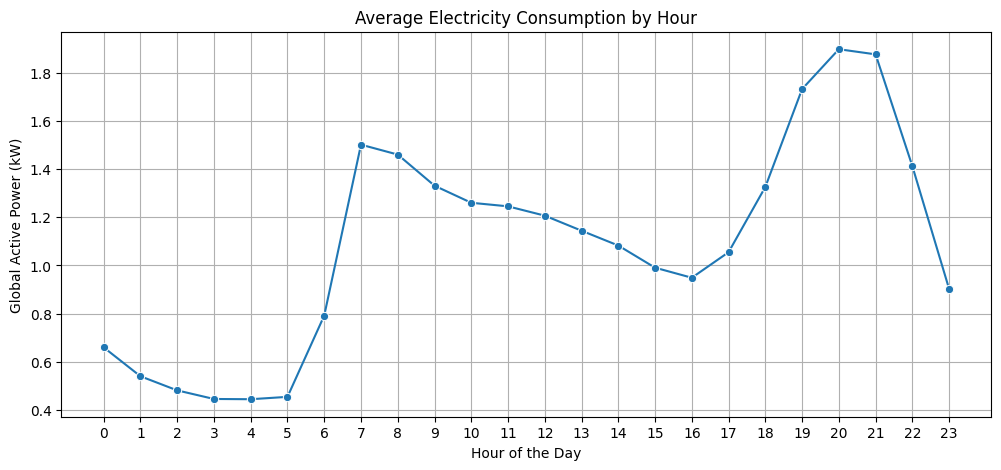

In [23]:

# Average electricity consumption by hour

hourly_consumption = (
    df_clean.groupby('Hour')['Global_active_power']
    .mean()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_consumption.index,
    y=hourly_consumption.values,
    marker='o'
)

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Global Active Power (kW)")
plt.xticks(range(24))
plt.grid(True)
plt.show()


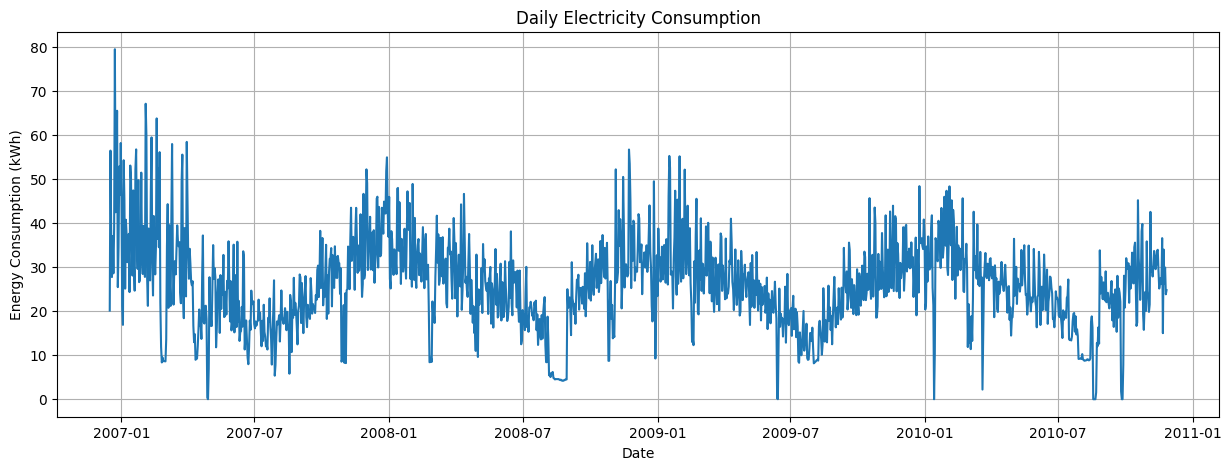

In [24]:

# Convert DateTime to datetime format

df_clean['DateTime'] = pd.to_datetime(df_clean['DateTime'])

# Calculate daily electricity consumption in kWh
daily_consumption = (
    df_clean.set_index('DateTime')['Global_active_power']
    .resample('D')
    .sum() / 60
)

plt.figure(figsize=(15, 5))

plt.plot(daily_consumption.index, daily_consumption.values)

plt.title("Daily Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh)")
plt.grid(True)
plt.show()


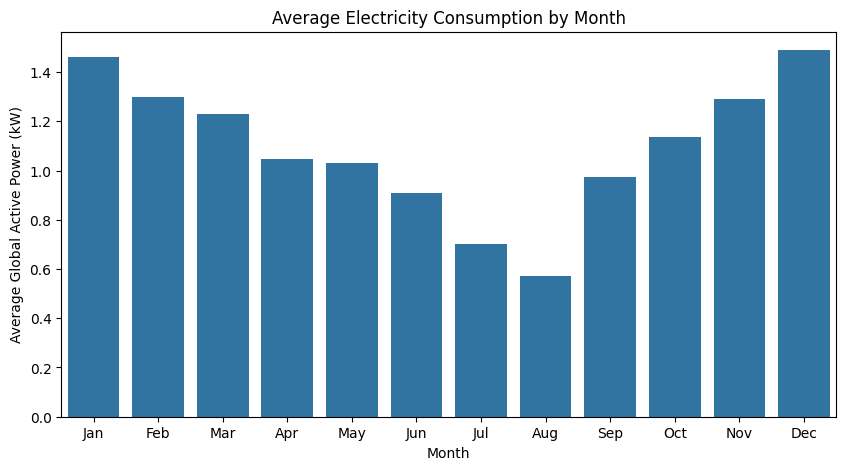

In [25]:

monthly_consumption = (
    df_clean.groupby('Month')['Global_active_power']
    .mean()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_consumption.index,
    y=monthly_consumption.values
)

plt.title("Average Electricity Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Global Active Power (kW)")
plt.xticks(range(12), [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
])

plt.show()


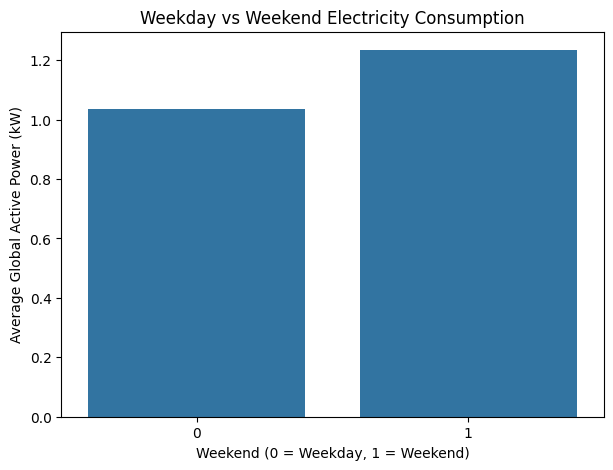

Is_Weekend
0    1.035472
1    1.234232
Name: Global_active_power, dtype: float64


In [26]:

weekend_comparison = (
    df_clean.groupby('Is_Weekend')['Global_active_power']
    .mean()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=weekend_comparison.index,
    y=weekend_comparison.values
)

plt.title("Weekday vs Weekend Electricity Consumption")
plt.xlabel("Weekend (0 = Weekday, 1 = Weekend)")
plt.ylabel("Average Global Active Power (kW)")

plt.show()

print(weekend_comparison)


In [27]:

# Select numerical columns
correlation_cols = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

# Calculate correlation matrix
correlation_matrix = df_clean[correlation_cols].corr()

print(correlation_matrix.round(2))


                       Global_active_power  Global_reactive_power  Voltage  \
Global_active_power                   1.00                   0.25    -0.40   
Global_reactive_power                 0.25                   1.00    -0.11   
Voltage                              -0.40                  -0.11     1.00   
Global_intensity                      1.00                   0.27    -0.41   
Sub_metering_1                        0.48                   0.12    -0.20   
Sub_metering_2                        0.43                   0.14    -0.17   
Sub_metering_3                        0.64                   0.09    -0.27   

                       Global_intensity  Sub_metering_1  Sub_metering_2  \
Global_active_power                1.00            0.48            0.43   
Global_reactive_power              0.27            0.12            0.14   
Voltage                           -0.41           -0.20           -0.17   
Global_intensity                   1.00            0.49            0.44   


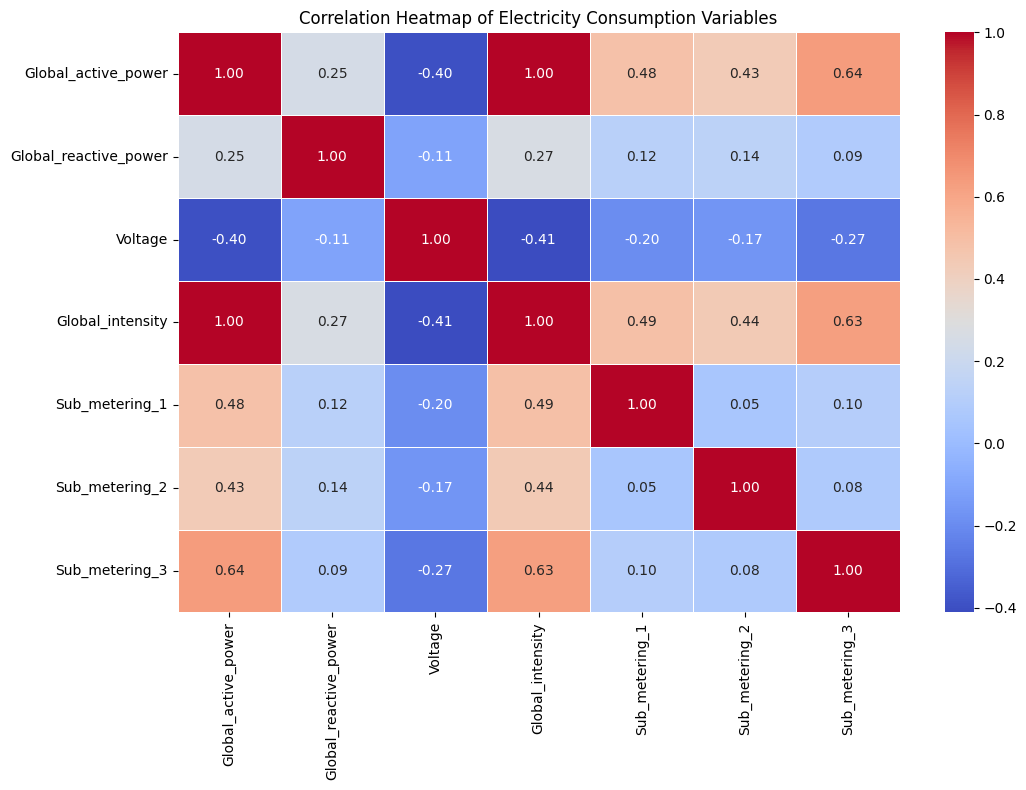

In [28]:

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Electricity Consumption Variables")
plt.tight_layout()
plt.show()


Average Sub-metering Consumption:
Sub_metering_1    1.121923
Sub_metering_2    1.298520
Sub_metering_3    6.458447
dtype: float64


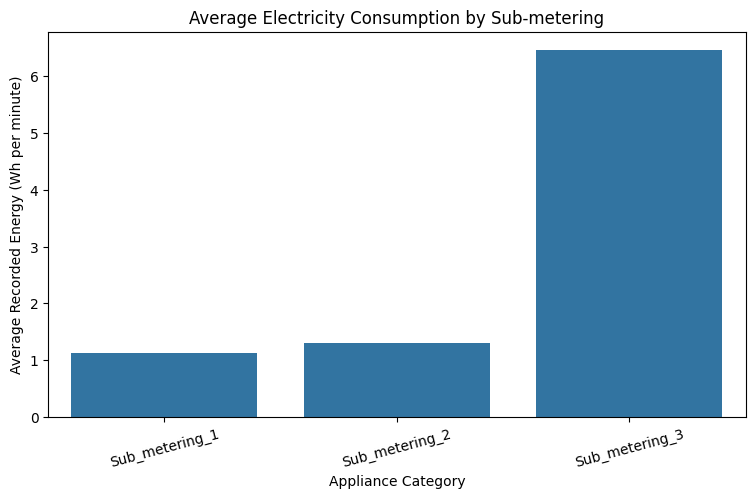

In [29]:

submetering_cols = [
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

submetering_avg = df_clean[submetering_cols].mean()

print("Average Sub-metering Consumption:")
print(submetering_avg)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=submetering_avg.index,
    y=submetering_avg.values
)

plt.title("Average Electricity Consumption by Sub-metering")
plt.xlabel("Appliance Category")
plt.ylabel("Average Recorded Energy (Wh per minute)")

plt.xticks(rotation=15)
plt.show()


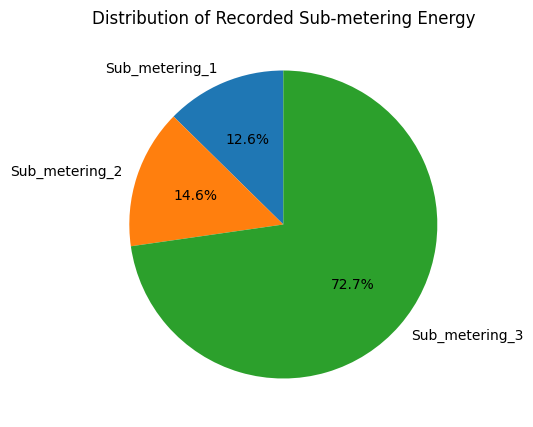

In [30]:

submetering_total = df_clean[submetering_cols].sum()

plt.figure(figsize=(8, 5))

plt.pie(
    submetering_total,
    labels=submetering_total.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Distribution of Recorded Sub-metering Energy")
plt.show()


In [31]:
# Statistical analysis of electricity consumption

columns = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

statistics = df_clean[columns].describe().T

statistics = statistics.round(3)

print("Electricity Consumption Statistical Summary:")
print(statistics)

Electricity Consumption Statistical Summary:
                           count     mean    std      min      25%      50%  \
Global_active_power    2049280.0    1.092  1.057    0.076    0.308    0.602   
Global_reactive_power  2049280.0    0.124  0.113    0.000    0.048    0.100   
Voltage                2049280.0  240.840  3.240  223.200  238.990  241.010   
Global_intensity       2049280.0    4.628  4.444    0.200    1.400    2.600   
Sub_metering_1         2049280.0    1.122  6.153    0.000    0.000    0.000   
Sub_metering_2         2049280.0    1.299  5.822    0.000    0.000    0.000   
Sub_metering_3         2049280.0    6.458  8.437    0.000    0.000    1.000   

                           75%      max  
Global_active_power      1.528   11.122  
Global_reactive_power    0.194    1.390  
Voltage                242.890  254.150  
Global_intensity         6.400   48.400  
Sub_metering_1           0.000   88.000  
Sub_metering_2           1.000   80.000  
Sub_metering_3          17.0

In [32]:
# Daily electricity consumption in kWh

df_clean['DateTime'] = pd.to_datetime(df_clean['DateTime'])

daily_consumption = (
    df_clean.groupby(df_clean['DateTime'].dt.date)
    ['Global_active_power']
    .sum() / 60
)

# Highest consumption days

print("Top 10 Highest Consumption Days:")
print(daily_consumption.nlargest(10).round(2))

# Lowest consumption days

print("\nTop 10 Lowest Consumption Days:")
print(daily_consumption.nsmallest(10).round(2))

Top 10 Highest Consumption Days:
DateTime
2006-12-23    79.56
2007-02-03    67.16
2006-12-26    65.57
2007-02-18    63.83
2007-02-04    59.93
2007-02-11    59.52
2007-03-31    58.49
2006-12-31    58.24
2007-03-11    58.01
2007-01-21    56.79
Name: Global_active_power, dtype: float64

Top 10 Lowest Consumption Days:
DateTime
2009-06-13    0.24
2007-04-28    0.38
2010-08-22    1.56
2010-09-25    1.77
2010-03-20    2.20
2008-08-25    4.17
2008-08-23    4.24
2008-08-24    4.25
2008-08-26    4.29
2008-08-27    4.30
Name: Global_active_power, dtype: float64


In [33]:
# Check number of readings recorded each day

df_clean['DateOnly'] = df_clean['DateTime'].dt.date

daily_records = df_clean.groupby('DateOnly').size()

print("Daily Record Count:")
print(daily_records.describe())

# Check days with fewer than 1400 readings

incomplete_days = daily_records[daily_records < 1400]

print("\nNumber of potentially incomplete days:")
print(len(incomplete_days))

print("\nDays with incomplete readings:")
print(incomplete_days.head(20))

Daily Record Count:
count    1433.000000
mean     1430.062805
std       102.208778
min        21.000000
25%      1440.000000
50%      1440.000000
75%      1440.000000
max      1440.000000
dtype: float64

Number of potentially incomplete days:
18

Days with incomplete readings:
DateOnly
2006-12-16     396
2007-04-28      21
2007-04-30     576
2007-07-15    1310
2008-10-25    1397
2008-12-10    1370
2009-06-13      30
2009-06-15     985
2009-08-13     549
2010-01-12     893
2010-01-14     298
2010-03-20     232
2010-03-21     621
2010-08-17    1262
2010-08-22     152
2010-09-25     236
2010-09-28     287
2010-11-26    1263
dtype: int64


In [34]:
# Calculate daily energy consumption

daily_energy = (
    df_clean.groupby('DateOnly')['Global_active_power'].sum() / 60
)

# Keep days with at least 1400 readings

complete_days = daily_records[daily_records >= 1400].index

valid_daily_energy = daily_energy.loc[complete_days]

print("Highest Consumption Days:")
print(valid_daily_energy.nlargest(10).round(2))

print("\nLowest Consumption Days:")
print(valid_daily_energy.nsmallest(10).round(2))

Highest Consumption Days:
DateOnly
2006-12-23    79.56
2007-02-03    67.16
2006-12-26    65.57
2007-02-18    63.83
2007-02-04    59.93
2007-02-11    59.52
2007-03-31    58.49
2006-12-31    58.24
2007-03-11    58.01
2007-01-21    56.79
Name: Global_active_power, dtype: float64

Lowest Consumption Days:
DateOnly
2008-08-25    4.17
2008-08-23    4.24
2008-08-24    4.25
2008-08-26    4.29
2008-08-27    4.30
2008-08-21    4.35
2008-08-22    4.45
2008-08-29    4.46
2008-08-28    4.47
2008-08-20    4.47
Name: Global_active_power, dtype: float64


      Average_Power  Total_Readings
Year                               
2006          1.901           21992
2007          1.117          521669
2008          1.072          526905
2009          1.079          521320
2010          1.061          457394


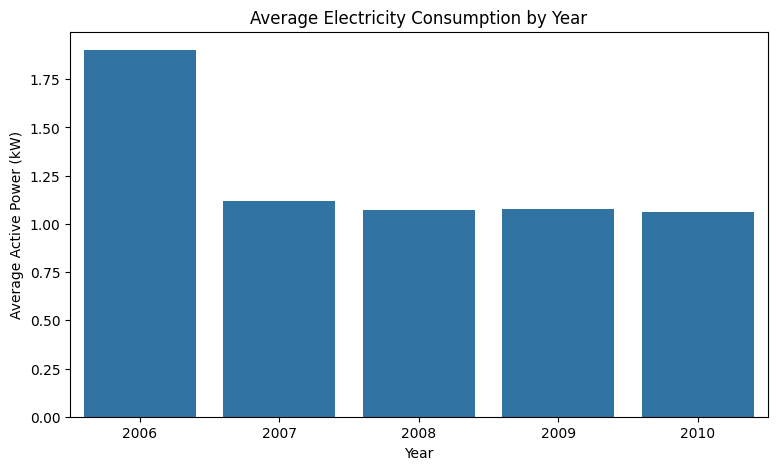

In [35]:
# YEARLY ELECTRICITY CONSUMPTION

df_clean['Year'] = df_clean['DateTime'].dt.year

yearly = df_clean.groupby('Year').agg(
    Average_Power=('Global_active_power', 'mean'),
    Total_Readings=('Global_active_power', 'count')
)

print(yearly.round(3))

plt.figure(figsize=(9,5))
sns.barplot(
    x=yearly.index,
    y=yearly['Average_Power']
)

plt.title("Average Electricity Consumption by Year")
plt.xlabel("Year")
plt.ylabel("Average Active Power (kW)")
plt.show()

Day_Name
Monday       1.000
Tuesday      1.070
Wednesday    1.083
Thursday     0.982
Friday       1.043
Saturday     1.248
Sunday       1.220
Name: Global_active_power, dtype: float64


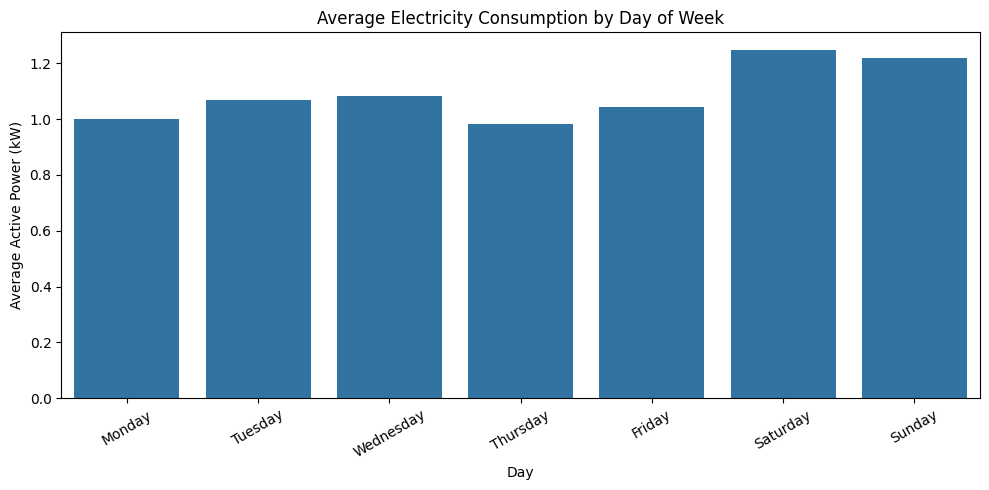

In [36]:
# CONSUMPTION BY DAY OF WEEK

df_clean['Day_Name'] = df_clean['DateTime'].dt.day_name()

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_data = (
    df_clean.groupby('Day_Name')['Global_active_power']
    .mean().reindex(weekday_order)
)

print(weekday_data.round(3))

plt.figure(figsize=(10,5))
sns.barplot(x=weekday_data.index, y=weekday_data.values)

plt.title("Average Electricity Consumption by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [37]:
# IDENTIFY PEAK CONSUMPTION PERIODS

hourly = df_clean.groupby('Hour')['Global_active_power'].mean()

peak_hour = hourly.idxmax()
lowest_hour = hourly.idxmin()

print("Peak consumption hour:", peak_hour)
print("Peak average power:", round(hourly.max(), 3), "kW")

print("\nLowest consumption hour:", lowest_hour)
print("Lowest average power:", round(hourly.min(), 3), "kW")

# Top 5 peak hours
print("\nTop 5 consumption hours:")
print(hourly.nlargest(5).round(3))

Peak consumption hour: 20
Peak average power: 1.899 kW

Lowest consumption hour: 4
Lowest average power: 0.444 kW

Top 5 consumption hours:
Hour
20    1.899
21    1.878
19    1.733
7     1.502
8     1.461
Name: Global_active_power, dtype: float64


Number of unusual consumption days: 28

Highest unusual consumption days:
               Energy  Records
DateTime                      
2006-12-23  79.556433     1440
2007-02-03  67.162033     1440
2006-12-26  65.568500     1440
2007-02-18  63.829367     1440
2007-02-04  59.932333     1440
2007-02-11  59.520467     1440
2007-03-31  58.491833     1440
2006-12-31  58.236600     1440
2007-03-11  58.010600     1440
2007-01-21  56.787700     1440


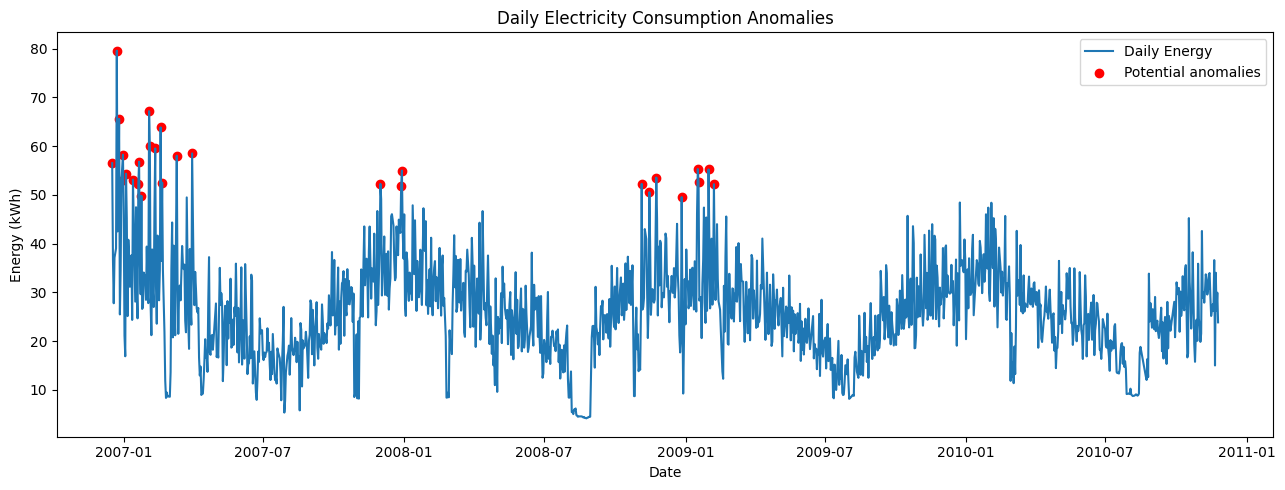

In [38]:
# DAILY ANOMALY DETECTION

daily_data = df_clean.groupby(
    df_clean['DateTime'].dt.date
).agg(
    Energy=('Global_active_power', lambda x: x.sum()/60),
    Records=('Global_active_power', 'count')
)

# Select complete days
daily_data = daily_data[daily_data['Records'] == 1440]

Q1 = daily_data['Energy'].quantile(0.25)
Q3 = daily_data['Energy'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

anomalies = daily_data[
    (daily_data['Energy'] < lower) |
    (daily_data['Energy'] > upper)
]

print("Number of unusual consumption days:", len(anomalies))
print("\nHighest unusual consumption days:")
print(anomalies.sort_values('Energy', ascending=False).head(10))

plt.figure(figsize=(13,5))
plt.plot(daily_data.index, daily_data['Energy'], label='Daily Energy')
plt.scatter(anomalies.index, anomalies['Energy'],
            color='red', label='Potential anomalies')

plt.title("Daily Electricity Consumption Anomalies")
plt.xlabel("Date")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
!git clone https://github.com/yashikavenugopal/Dev-AAT.git


Cloning into 'Dev-AAT'...


In [41]:
%cd Dev-AAT


/content/Dev-AAT


In [42]:
!git checkout -b electricity-analysis


Switched to a new branch 'electricity-analysis'


In [44]:
!git branch


In [45]:
!ls /content

Dev-AAT  household_power_consumption.txt  sample_data


In [46]:
from google.colab import files
uploaded = files.upload()